# Vision-to-Text Pipeline: ViT Scene Classification + LLM Descriptions
**Arman Aryafar**

This notebook builds a pipeline that goes from an image to a text description. First I fine-tune a Vision Transformer on the Intel Image Classification dataset (saved locally as `Objects/`), which has six scene classes (buildings, forest, glacier, mountain, sea, street). The ViT's predicted class is then passed to a small LLM that writes a few sentences describing it. To keep the LLM from making things up, the pipeline skips the description if the ViT is less than 60% confident, and the LLM uses fixed (non-random) decoding with repetition limits so it doesn't loop.

Folder layout the notebook expects (same folder as this notebook):
```
Objects/
    train/  buildings/ forest/ glacier/ mountain/ sea/ street/
    test/   buildings/ forest/ glacier/ mountain/ sea/ street/
    new/    building.jpg forest.jpg glacier.jpg ... (new images to describe)
```

Dependencies are listed in `requirements.txt` (`pip install -r requirements.txt`).

## Setup

In [1]:
import os
import glob
import random

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from datasets import load_dataset
from transformers import (
    AutoImageProcessor,
    AutoModelForImageClassification,
    AutoTokenizer,
    AutoModelForCausalLM,
    TrainingArguments,
    Trainer,
    set_seed,
)
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
# paths and settings, everything tweakable lives here
DATA_DIR = "Objects"
TRAIN_DIR = os.path.join(DATA_DIR, "train")
TEST_DIR = os.path.join(DATA_DIR, "test")
NEW_DIR = os.path.join(DATA_DIR, "new")

# google's vit base, already pretrained on imagenet-21k and fine-tuned on imagenet-1k
VIT_CHECKPOINT = "google/vit-base-patch16-224"
# small base llm (~0.5B params) for the text bridge, light enough for a laptop
LLM_CHECKPOINT = "Qwen/Qwen2.5-0.5B"

MODEL_SAVE_DIR = "vit_objects_model"

# the full train set is ~14k images which takes a while on a laptop.
# capping images per class keeps training time manageable (about an hour on an m-series mac for 3 epochs).
# set to None to train on everything
MAX_TRAIN_PER_CLASS = 800
MAX_TEST_PER_CLASS = None   # None means evaluate on the whole test folder

NUM_EPOCHS = 3
CONF_THRESHOLD = 0.60
SEED = 42

set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)

# pick the best device available (apple silicon -> mps, nvidia -> cuda, otherwise cpu)
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"
print("using device:", device)

using device: mps


## Step 1: Training the Vision Transformer

### Load the dataset with `load_dataset("imagefolder")`
Each split folder has one subfolder per class, so the `imagefolder` builder reads the folder names as labels. I load train and test separately (instead of pointing it at `Objects/` as a whole) so the unlabeled `new/` folder doesn't get pulled into training by accident.

In [3]:
train_ds = load_dataset("imagefolder", data_dir=TRAIN_DIR, split="train")
test_ds = load_dataset("imagefolder", data_dir=TEST_DIR, split="train")

labels = train_ds.features["label"].names
# make sure both splits agree on the label order, otherwise the evaluation would be garbage
assert labels == test_ds.features["label"].names, "train and test class folders don't match"

id2label = {i: name for i, name in enumerate(labels)}
label2id = {name: i for i, name in enumerate(labels)}

print("classes:", labels)
print("train images:", len(train_ds), "| test images:", len(test_ds))
print(pd.Series(train_ds["label"]).map(id2label).value_counts().sort_index())

classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
train images: 14034 | test images: 3000
buildings    2191
forest       2271
glacier      2404
mountain     2512
sea          2274
street       2382
Name: count, dtype: int64


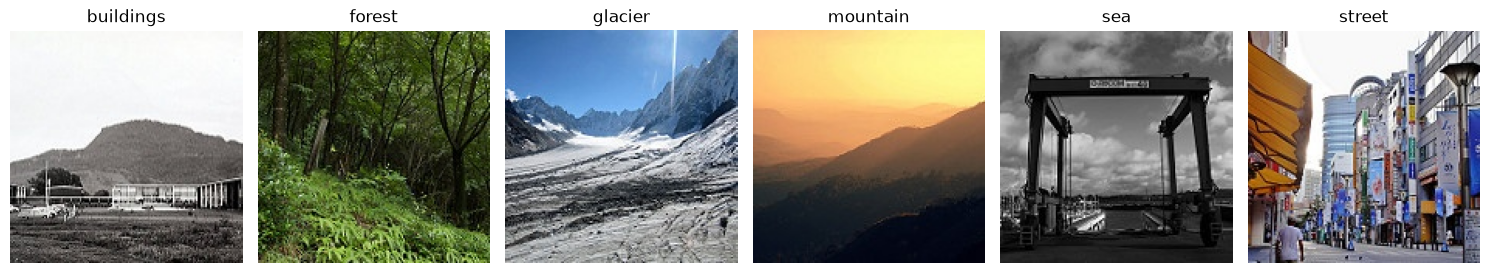

In [4]:
# quick look at a few training images so we know what the model is seeing
fig, axes = plt.subplots(1, 6, figsize=(15, 3))
for ax, class_id in zip(axes, range(len(labels))):
    idx = int(np.where(np.array(train_ds["label"]) == class_id)[0][0])
    ax.imshow(train_ds[idx]["image"])
    ax.set_title(id2label[class_id])
    ax.axis("off")
plt.tight_layout()
plt.show()

In [5]:
# take a balanced random sample per class (keeps the classes even and training fast)
def sample_per_class(ds, n_per_class, seed=SEED):
    if n_per_class is None:
        return ds
    rng = np.random.default_rng(seed)
    all_labels = np.array(ds["label"])
    keep = []
    for class_id in np.unique(all_labels):
        idx = np.where(all_labels == class_id)[0]
        keep.extend(rng.choice(idx, size=min(n_per_class, len(idx)), replace=False).tolist())
    return ds.select(sorted(keep))

train_ds = sample_per_class(train_ds, MAX_TRAIN_PER_CLASS)
test_ds = sample_per_class(test_ds, MAX_TEST_PER_CLASS)
print("train images used:", len(train_ds), "| test images used:", len(test_ds))

train images used: 4800 | test images used: 3000


### Preprocess with `AutoImageProcessor`
The images have to be prepped exactly like the checkpoint's original training data (resize to 224x224, same mean/std normalization), so the processor for that checkpoint does it. I use `with_transform` so images get processed on the fly per batch instead of storing thousands of tensors in memory. Training images also get a random horizontal flip as a tiny bit of augmentation (a flipped forest is still a forest).

In [6]:
processor = AutoImageProcessor.from_pretrained(VIT_CHECKPOINT)

def train_transform(batch):
    images = []
    for img in batch["image"]:
        img = img.convert("RGB")   # a few images can be grayscale, the model wants 3 channels
        if random.random() < 0.5:
            img = img.transpose(Image.FLIP_LEFT_RIGHT)
        images.append(img)
    inputs = processor(images, return_tensors="pt")
    inputs["labels"] = batch["label"]
    return inputs

def eval_transform(batch):
    images = [img.convert("RGB") for img in batch["image"]]
    inputs = processor(images, return_tensors="pt")
    inputs["labels"] = batch["label"]
    return inputs

encoded_train = train_ds.with_transform(train_transform)
encoded_val = test_ds.with_transform(eval_transform)

# the collator stacks individual examples into one batch tensor for the model
def collate_fn(examples):
    return {
        "pixel_values": torch.stack([ex["pixel_values"] for ex in examples]),
        "labels": torch.tensor([ex["labels"] for ex in examples]),
    }

print(encoded_train[0]["pixel_values"].shape)

torch.Size([3, 224, 224])


### Model + fine-tuning with `Trainer` and `TrainingArguments`
`AutoModelForImageClassification` loads the pretrained ViT and swaps the 1000-class ImageNet head for a new 6-class head (`ignore_mismatched_sizes=True` is what allows the swap). The whole network gets fine-tuned with a small learning rate so the pretrained features don't get wrecked.

In [7]:
model = AutoModelForImageClassification.from_pretrained(
    VIT_CHECKPOINT,
    num_labels=len(labels),
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True,   # replaces the old imagenet head with our 6 class head
)

# the metric the trainer reports after every epoch
def compute_metrics(eval_pred):
    logits, label_ids = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(label_ids, preds)}

training_args = TrainingArguments(
    output_dir="vit_objects_checkpoints",
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=NUM_EPOCHS,
    learning_rate=3e-5,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,       # keeps the epoch with the best test accuracy
    metric_for_best_model="accuracy",
    save_total_limit=1,
    logging_steps=25,
    remove_unused_columns=False,       # needed since the pixel_values come from with_transform
    dataloader_num_workers=0,          # safer inside jupyter on a mac
    report_to="none",
    seed=SEED,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=encoded_train,
    eval_dataset=encoded_val,
    data_collator=collate_fn,
    compute_metrics=compute_metrics,
    processing_class=processor,
)

train_result = trainer.train()
print(train_result.metrics)

Epoch,Training Loss,Validation Loss,Accuracy
1,0.097401,0.179358,0.939667
2,0.106625,0.175313,0.949333
3,0.024411,0.175036,0.951000


{'train_runtime': 3899.9985, 'train_samples_per_second': 3.692, 'train_steps_per_second': 0.231, 'total_flos': 1.115924655734784e+18, 'train_loss': 0.13165825767649544, 'epoch': 3.0}


### Save the trained model

In [8]:
# saves config.json, the weights, and the image processor settings together
trainer.save_model(MODEL_SAVE_DIR)
processor.save_pretrained(MODEL_SAVE_DIR)
print("saved to", os.path.abspath(MODEL_SAVE_DIR))
print(os.listdir(MODEL_SAVE_DIR))

saved to ./vit_objects_model
['model.safetensors', 'config.json', 'training_args.bin', 'preprocessor_config.json']


## Step 2: Evaluating Model Performance
Running `trainer.predict` on both the training data and the held-out test split. Comparing the two also shows whether the model is overfitting (train way higher than test).

In [9]:
train_out = trainer.predict(encoded_train)
val_out = trainer.predict(encoded_val)

# ground truth labels and predicted class ids
y_train_true = train_out.label_ids
y_train_pred = np.argmax(train_out.predictions, axis=-1)
y_val_true = val_out.label_ids
y_val_pred = np.argmax(val_out.predictions, axis=-1)

print(f"train accuracy: {accuracy_score(y_train_true, y_train_pred):.4f}")
print(f"test accuracy:  {accuracy_score(y_val_true, y_val_pred):.4f}")
print()
print(classification_report(y_val_true, y_val_pred, target_names=labels, digits=3))

train accuracy: 0.9952
test accuracy:  0.9510

              precision    recall  f1-score   support

   buildings      0.954     0.943     0.948       437
      forest      0.996     0.996     0.996       474
     glacier      0.923     0.906     0.914       553
    mountain      0.913     0.918     0.915       525
         sea      0.977     0.984     0.980       510
      street      0.951     0.966     0.958       501

    accuracy                          0.951      3000
   macro avg      0.952     0.952     0.952      3000
weighted avg      0.951     0.951     0.951      3000



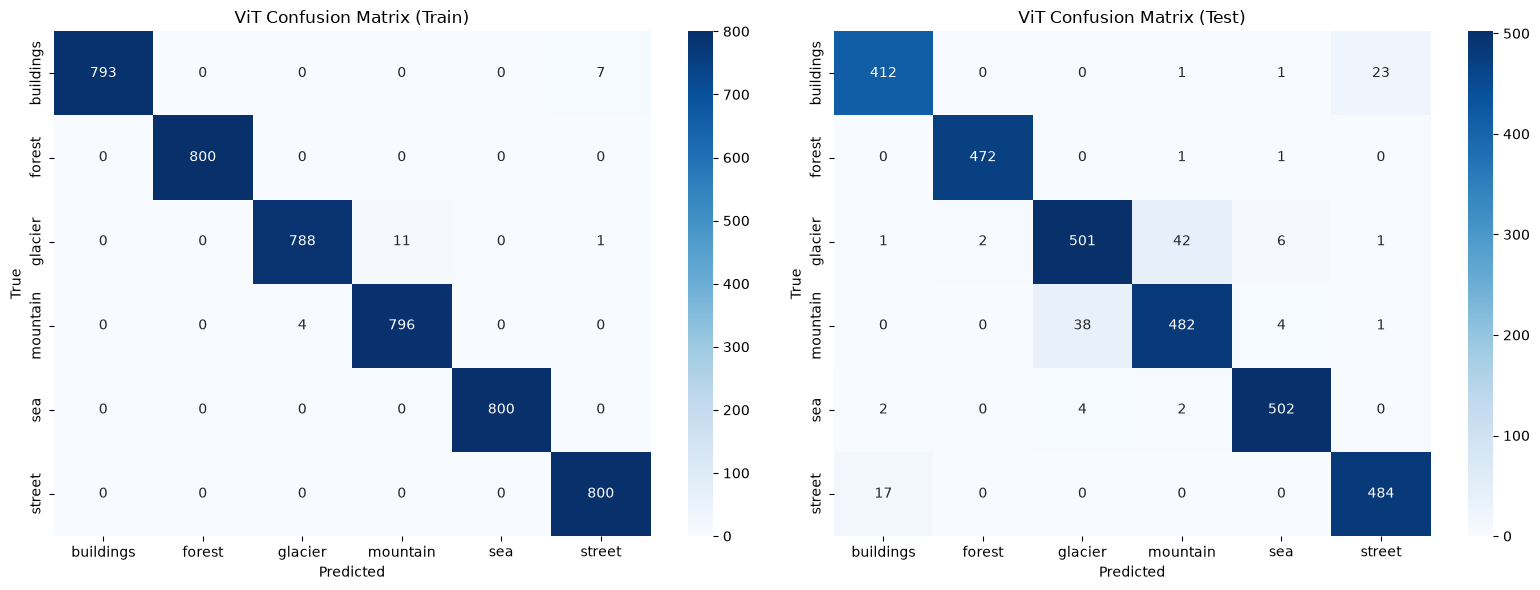

In [10]:
# confusion matrices for both splits side by side
cm_train = confusion_matrix(y_train_true, y_train_pred, labels=range(len(labels)))
cm_val = confusion_matrix(y_val_true, y_val_pred, labels=range(len(labels)))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, cm, title in [(axes[0], cm_train, "Train"), (axes[1], cm_val, "Test")]:
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_title(f"ViT Confusion Matrix ({title})")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=150)
plt.show()

In [11]:
# pull out which class pairs get mixed up the most on the test split
mistakes = []
for i in range(len(labels)):
    for j in range(len(labels)):
        if i != j and cm_val[i, j] > 0:
            mistakes.append((labels[i], labels[j], int(cm_val[i, j]), cm_val[i, j] / cm_val[i].sum()))

mistakes_df = pd.DataFrame(mistakes, columns=["true", "predicted_as", "count", "pct_of_true_class"])
mistakes_df = mistakes_df.sort_values("count", ascending=False).reset_index(drop=True)
mistakes_df["pct_of_true_class"] = (mistakes_df["pct_of_true_class"] * 100).round(1)
mistakes_df.head(8)

,true,predicted_as,count,pct_of_true_class
0,glacier,mountain,42,7.6
1,mountain,glacier,38,7.2
2,buildings,street,23,5.3
3,street,buildings,17,3.4
4,glacier,sea,6,1.1
5,mountain,sea,4,0.8
6,sea,glacier,4,0.8
7,glacier,forest,2,0.4


**Which classes does the ViT struggle with?**

Test accuracy came out to 95.1% (train 99.5%), so the model is solid overall, but the errors aren't random. They cluster into two pairs that actually look alike:

- **glacier vs mountain** is the biggest problem. 42 glacier images (7.6%) got called mountain and 38 mountain images (7.2%) got called glacier. These two had the lowest F1 scores (0.914 and 0.915). Snowy peaks show up in both classes, so a lot of these images could honestly fit either label.
- **buildings vs street** is second. 23 buildings images (5.3%) were predicted as street and 17 street images (3.4%) as buildings. Street photos almost always have buildings in them and building photos often show a street, so it comes down to what the main subject is.
- Sea only gets mixed up a handful of times with glacier and mountain (water next to ice or peaks).
- Forest is basically perfect at 99.6% since nothing else is mostly trees.

The train vs test gap (99.5% vs 95.1%) shows a little overfitting, but test accuracy still holds up well on images the model never saw during training.

## Step 3: The LLM Text Bridge and Anti-Hallucination Guardrails

### Load the saved ViT + a lightweight LLM
Loading the ViT back from disk (not reusing the in-memory one) proves the saved model actually works on its own. For the LLM I used Qwen2.5-0.5B, a small base model that's good at continuing text, which is exactly what the structured prompt template needs.

In [12]:
# the fine-tuned vit, loaded fresh from the saved folder
vit_processor = AutoImageProcessor.from_pretrained(MODEL_SAVE_DIR)
vit_model = AutoModelForImageClassification.from_pretrained(MODEL_SAVE_DIR).to(device)
vit_model.eval()
vit_id2label = vit_model.config.id2label

# the generative llm
llm_tokenizer = AutoTokenizer.from_pretrained(LLM_CHECKPOINT)
llm_model = AutoModelForCausalLM.from_pretrained(LLM_CHECKPOINT).to(device)
llm_model.eval()
if llm_tokenizer.pad_token is None:
    llm_tokenizer.pad_token = llm_tokenizer.eos_token

print("vit labels:", vit_id2label)
print("llm loaded:", LLM_CHECKPOINT)

vit labels: {0: 'buildings', 1: 'forest', 2: 'glacier', 3: 'mountain', 4: 'sea', 5: 'street'}
llm loaded: Qwen/Qwen2.5-0.5B


### Guardrails + inference function

**Guardrail 1, confidence threshold:** if the ViT's softmax confidence is below 0.60 the pipeline stops and never calls the LLM. That way the LLM can't be forced to confidently describe something the ViT probably got wrong.

**Guardrail 2, deterministic anti-hallucination and anti-looping:**
- the prompt is a fixed structural template, `Description of a [class]: The [class] is typically`, so the LLM only finishes a sentence about the predicted class instead of free-writing
- `do_sample=False` means greedy decoding, same input always gives the same output (no random creativity)
- `repetition_penalty=1.3` pushes the model away from reusing tokens it already generated
- `no_repeat_ngram_size=3` hard blocks any 3-word sequence from showing up twice, which kills the infinite-loop problem
- `max_new_tokens` caps the length, and the output is trimmed to complete sentences only (max 3) so nothing ends mid-sentence

In [13]:
# folder names like "buildings" read weird in a sentence ("a buildings"), so map them to nicer nouns
CLASS_NOUNS = {
    "buildings": "building",
    "forest": "forest",
    "glacier": "glacier",
    "mountain": "mountain",
    "sea": "sea",
    "street": "street",
}

def with_article(noun):
    return ("an " if noun[0].lower() in "aeiou" else "a ") + noun

def clean_sentences(text, max_sentences=3):
    # keep only the first paragraph, then only complete sentences
    text = text.strip().split("\n")[0].strip()
    sentences, current = [], ""
    for ch in text:
        current += ch
        if ch in ".!?":
            sentences.append(current.strip())
            current = ""
            if len(sentences) == max_sentences:
                break
    # if the llm never finished a sentence, keep what it wrote and close it off
    if not sentences and current.strip():
        sentences.append(current.strip().rstrip(",;:") + ".")
    # drop exact duplicate sentences just in case
    seen, unique = set(), []
    for s in sentences:
        if s.lower() not in seen:
            seen.add(s.lower())
            unique.append(s)
    return " ".join(unique)

def generate_description(label):
    noun = CLASS_NOUNS.get(label, label)
    stem = f"The {noun} is typically"
    prompt = f"Description of {with_article(noun)}: {stem}"

    inputs = llm_tokenizer(prompt, return_tensors="pt").to(device)
    with torch.no_grad():
        output_ids = llm_model.generate(
            **inputs,
            max_new_tokens=80,
            do_sample=False,              # greedy decoding, no randomness
            repetition_penalty=1.3,       # discourages reusing tokens
            no_repeat_ngram_size=3,       # blocks any repeated 3-word phrase
            pad_token_id=llm_tokenizer.pad_token_id,
            eos_token_id=llm_tokenizer.eos_token_id,
        )
    # only decode the new tokens, not the prompt
    new_tokens = output_ids[0][inputs["input_ids"].shape[1]:]
    continuation = llm_tokenizer.decode(new_tokens, skip_special_tokens=True)
    description = clean_sentences(stem + continuation)

    # if the llm gave back nothing usable, fall back instead of showing junk
    if description == "" or description == stem:
        description = f"No reliable description generated for {with_article(noun)}."
    return prompt, description

In [14]:
def classify_image(image):
    # runs the vit and returns (label, confidence, all class probabilities)
    inputs = vit_processor(image, return_tensors="pt").to(device)
    with torch.no_grad():
        logits = vit_model(**inputs).logits
    probs = torch.softmax(logits, dim=-1)[0].cpu()
    conf, idx = probs.max(dim=0)
    return vit_id2label[int(idx)], float(conf), probs

def describe_image(image_path, threshold=CONF_THRESHOLD, show=True):
    # full pipeline: image -> vit prediction + confidence -> guardrail -> llm description
    image = Image.open(image_path).convert("RGB")
    label, conf, probs = classify_image(image)

    if conf < threshold:
        status = "ABORTED (low confidence)"
        prompt, description = None, (f"Confidence {conf:.2f} is below the {threshold:.2f} threshold, "
                                     "so no description was generated.")
    else:
        status = "OK"
        prompt, description = generate_description(label)

    if show:
        # left side: the image, right side: probability for every class
        fig, (ax_img, ax_bar) = plt.subplots(1, 2, figsize=(11, 4),
                                             gridspec_kw={"width_ratios": [1, 1.2]})
        ax_img.imshow(image)
        ax_img.axis("off")
        ax_img.set_title(f"{os.path.basename(image_path)}\nPrediction: {label} ({conf:.1%})")
        class_names = [vit_id2label[i] for i in range(len(probs))]
        colors = ["tab:green" if n == label else "tab:gray" for n in class_names]
        ax_bar.barh(class_names, probs.numpy(), color=colors)
        ax_bar.axvline(threshold, color="red", linestyle="--", label=f"threshold {threshold}")
        ax_bar.set_xlim(0, 1)
        ax_bar.set_xlabel("softmax probability")
        ax_bar.legend(loc="lower right")
        plt.tight_layout()
        plt.show()

        print(f"Image:       {os.path.basename(image_path)}")
        print(f"Prediction:  {label}")
        print(f"Confidence:  {conf:.4f}")
        print(f"Status:      {status}")
        if prompt:
            print(f"Prompt:      {prompt}")
        print(f"Description: {description}")
        print("-" * 90)

    return {"file": os.path.basename(image_path), "prediction": label,
            "confidence": round(conf, 4), "status": status, "description": description}

### Run the full pipeline on the `new` images
Every image in `Objects/new/` goes through image -> ViT -> guardrail -> LLM. The filenames hint at what each image is (forest.jpg, street1.jpg, ...), so I use them as an expected label to double check every prediction is right.

found 8 new images


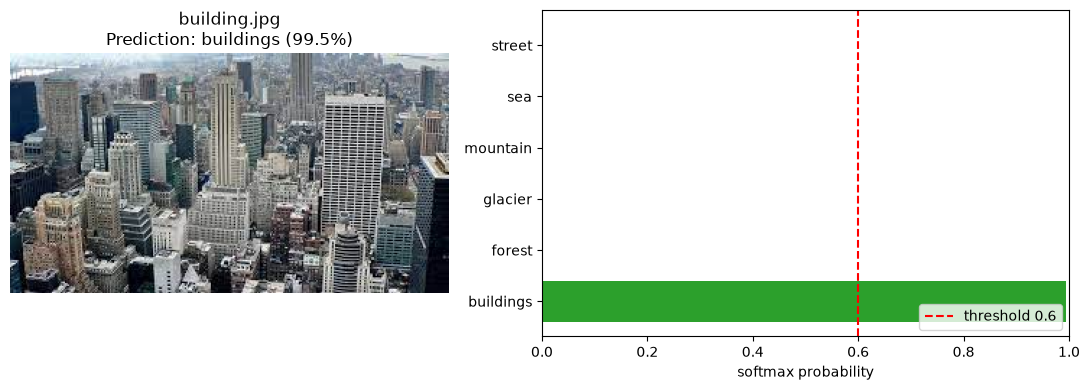

Image:       building.jpg
Prediction:  buildings
Confidence:  0.9951
Status:      OK
Prompt:      Description of a building: The building is typically
Description: The building is typically located in the heart of an urban area, with high traffic and pedestrian density. It may be surrounded by other buildings or have multiple entrances.
------------------------------------------------------------------------------------------


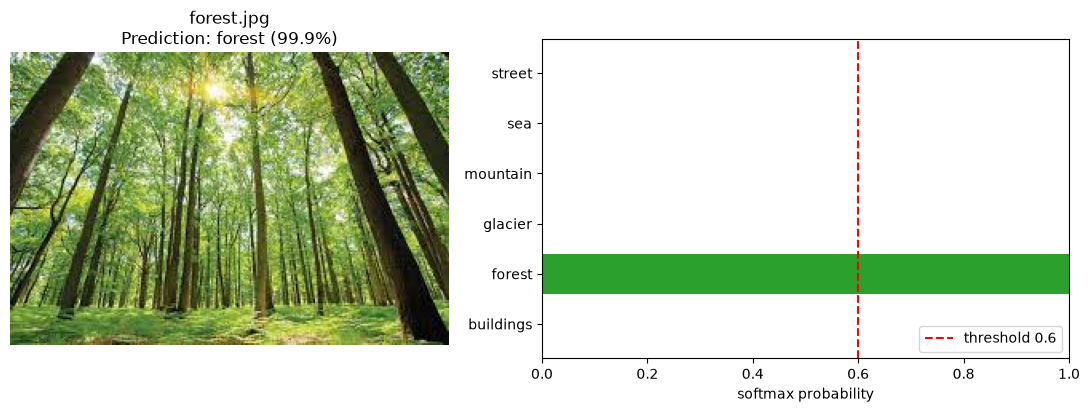

Image:       forest.jpg
Prediction:  forest
Confidence:  0.9995
Status:      OK
Prompt:      Description of a forest: The forest is typically
Description: The forest is typically composed of trees, shrubs and grasses. It can be found in many different types of environments such as mountains or deserts.
------------------------------------------------------------------------------------------


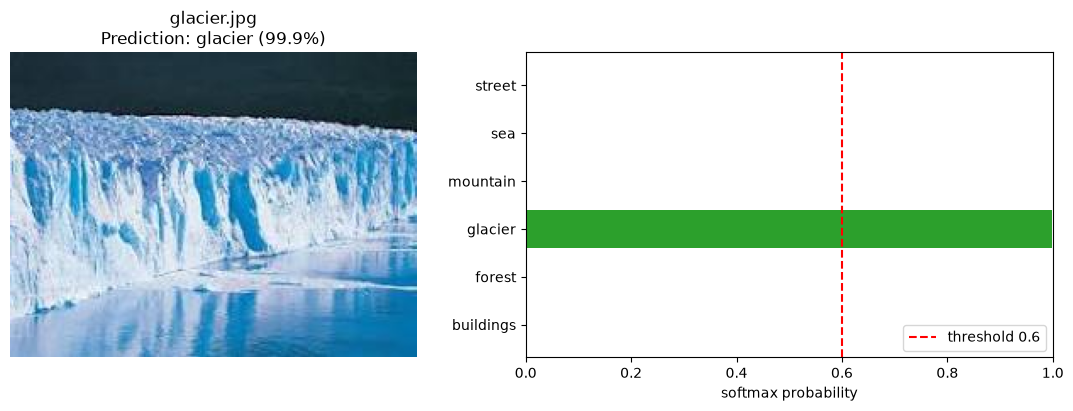

Image:       glacier.jpg
Prediction:  glacier
Confidence:  0.9985
Status:      OK
Prompt:      Description of a glacier: The glacier is typically
Description: The glacier is typically composed of ice and snow, with the majority being in its upper layers. It can be found on land or sea.
------------------------------------------------------------------------------------------


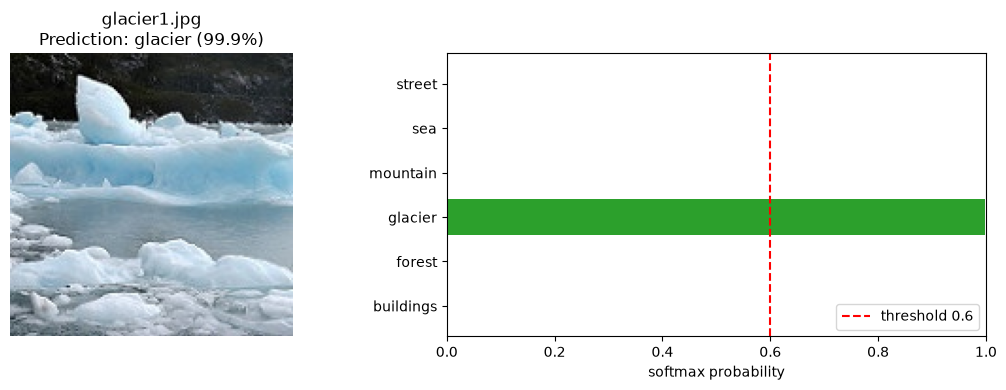

Image:       glacier1.jpg
Prediction:  glacier
Confidence:  0.9989
Status:      OK
Prompt:      Description of a glacier: The glacier is typically
Description: The glacier is typically composed of ice and snow, with the majority being in its upper layers. It can be found on land or sea.
------------------------------------------------------------------------------------------


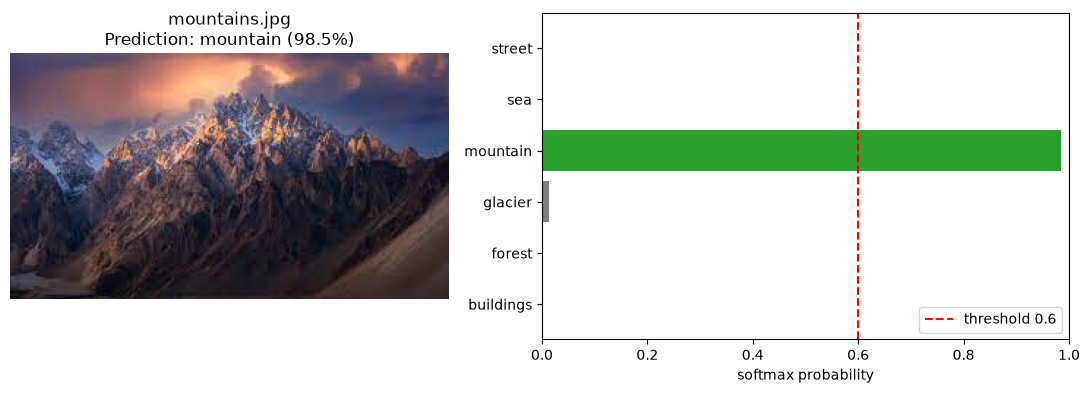

Image:       mountains.jpg
Prediction:  mountain
Confidence:  0.9852
Status:      OK
Prompt:      Description of a mountain: The mountain is typically
Description: The mountain is typically characterized by its height, the type and extent to which it rises above sea level (elevation), as well as any notable features such as peaks or valleys. It can also be described based on other factors like terrain complexity.
------------------------------------------------------------------------------------------


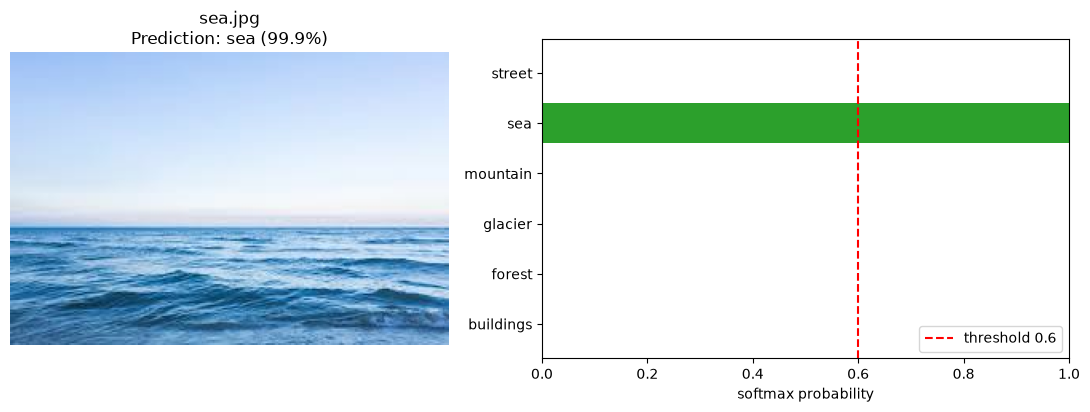

Image:       sea.jpg
Prediction:  sea
Confidence:  0.9993
Status:      OK
Prompt:      Description of a sea: The sea is typically
Description: The sea is typically described as an ocean, but it can also be defined by its depth and the presence or absence of life. It's important to note that there are many different types of seas around the world.
------------------------------------------------------------------------------------------


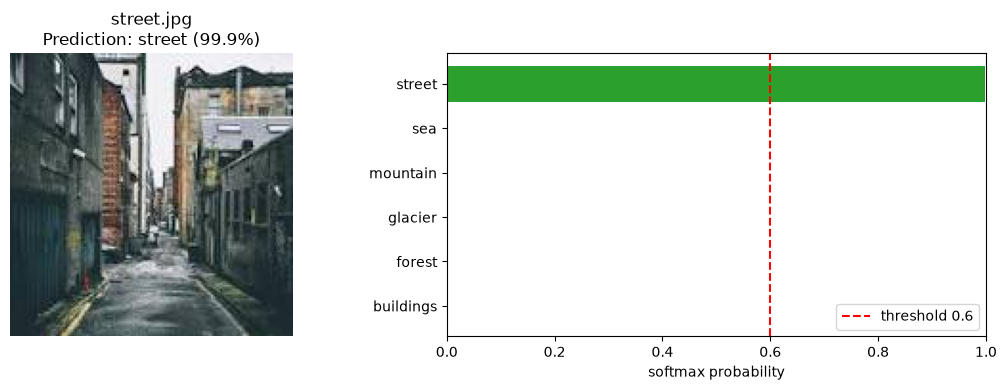

Image:       street.jpg
Prediction:  street
Confidence:  0.9987
Status:      OK
Prompt:      Description of a street: The street is typically
Description: The street is typically lined with buildings, and the streets are often wide enough for cars to drive on. There may be sidewalks or pedestrian walkways in some areas.
------------------------------------------------------------------------------------------


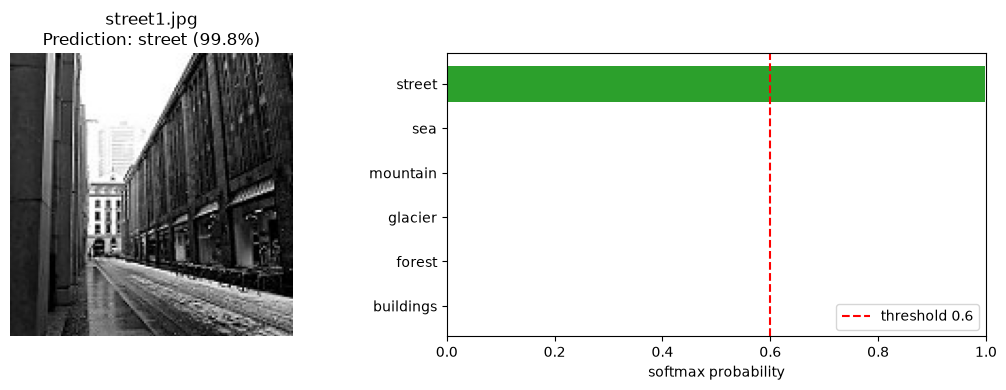

Image:       street1.jpg
Prediction:  street
Confidence:  0.9975
Status:      OK
Prompt:      Description of a street: The street is typically
Description: The street is typically lined with buildings, and the streets are often wide enough for cars to drive on. There may be sidewalks or pedestrian walkways in some areas.
------------------------------------------------------------------------------------------


In [15]:
new_images = sorted(
    p for p in glob.glob(os.path.join(NEW_DIR, "*"))
    if p.lower().endswith((".jpg", ".jpeg", ".png"))
)
print(f"found {len(new_images)} new images")

results = [describe_image(p) for p in new_images]

In [16]:
# expected label from the filename, e.g. "mountains.jpg" -> mountain, "street1.jpg" -> street
def expected_from_filename(fname):
    stem = os.path.splitext(fname)[0].rstrip("0123456789").lower()
    for lab in labels:
        if lab.startswith(stem) or stem.startswith(lab):
            return lab
    return None

summary = pd.DataFrame(results)[["file", "prediction", "confidence", "status"]]
summary["expected"] = summary["file"].apply(expected_from_filename)
summary["correct"] = summary["prediction"] == summary["expected"]
print(f"{summary['correct'].sum()} / {len(summary)} new images classified correctly")
summary

8 / 8 new images classified correctly


,file,prediction,confidence,status,expected,correct
0,building.jpg,buildings,0.9951,OK,buildings,True
1,forest.jpg,forest,0.9995,OK,forest,True
2,glacier.jpg,glacier,0.9985,OK,glacier,True
3,glacier1.jpg,glacier,0.9989,OK,glacier,True
4,mountains.jpg,mountain,0.9852,OK,mountain,True
5,sea.jpg,sea,0.9993,OK,sea,True
6,street.jpg,street,0.9987,OK,street,True
7,street1.jpg,street,0.9975,OK,street,True


### Guardrail check: an ambiguous image
To test the confidence threshold, this blends a forest image and a sea image 50/50 into one picture. Interestingly the ViT still predicted sea with 98.7% confidence, so the guardrail didn't need to abort here. This shows a limitation of softmax confidence: the model can be very confident even on an image that's half one class and half another. The threshold still protects the LLM whenever the ViT is actually unsure (below 0.60), and on all 8 real images the confidence was above 0.98, so every description was generated from a confident prediction.

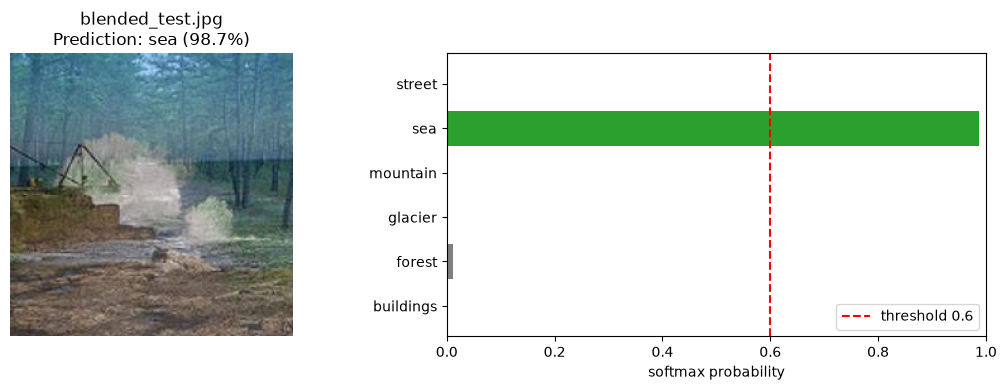

Image:       blended_test.jpg
Prediction:  sea
Confidence:  0.9867
Status:      OK
Prompt:      Description of a sea: The sea is typically
Description: The sea is typically described as an ocean, but it can also be defined by its depth and the presence or absence of life. It's important to note that there are many different types of seas around the world.
------------------------------------------------------------------------------------------


In [17]:
# blend a forest and a sea image from the test split into one ambiguous image
def first_image_of(class_name):
    folder = os.path.join(TEST_DIR, class_name)
    return sorted(glob.glob(os.path.join(folder, "*.jpg")))[0]

img_a = Image.open(first_image_of("forest")).convert("RGB").resize((224, 224))
img_b = Image.open(first_image_of("sea")).convert("RGB").resize((224, 224))
Image.blend(img_a, img_b, alpha=0.5).save("blended_test.jpg")

_ = describe_image("blended_test.jpg")

## Summary
- **Step 1:** fine-tuned `google/vit-base-patch16-224` on the Intel scene dataset with the HF `Trainer`, saved to `vit_objects_model/`.
- **Step 2:** evaluated with `trainer.predict` on train and test, plotted confusion matrices, and listed the class pairs the model mixes up.
- **Step 3:** loaded the saved ViT and Qwen2.5-0.5B, then built `describe_image()` which shows the image, prediction, and confidence, and only calls the LLM when confidence is at least 0.60. Generation is deterministic (`do_sample=False`) with `repetition_penalty` and `no_repeat_ngram_size` so descriptions stay on topic and never loop.